# Forecasting Daily Patient Arrivals at an Emergency Department

Daily arrivals from 1 January 2014. The notebook looks at autocorrelation, decomposes the series
into trend, seasonal and residual parts, and compares three forecasting methods on a 7-day and a
30-day horizon:

- Exponential smoothing (additive trend, multiplicative weekly seasonality)
- ARIMA, with the order chosen on a validation window
- K-nearest-neighbour regression on 5 lagged values

Forecasts are scored with the mean absolute percentage error (MAPE) on the last 7 or 30 days.
Outputs are from the original run.

## 1. Autocorrelation

            Arrivals
Date                
2014-01-01        90
2014-01-02        97
2014-01-03        80
2014-01-04        92
2014-01-05        76

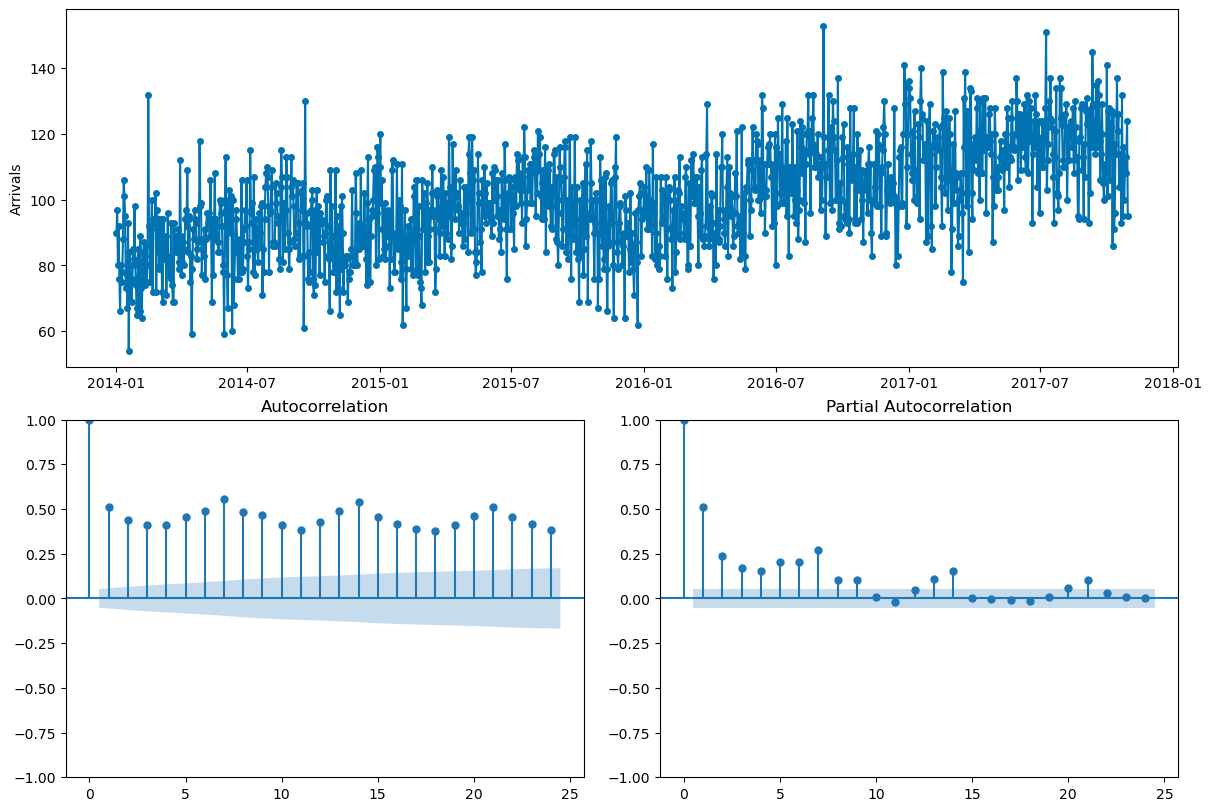

In [ ]:
import numpy as np
import pandas as pd
from sktime.utils.plotting import plot_correlations

df = pd.read_csv("ed_time_series.csv")  # daily arrivals; not included in this repository
df["Date"] = pd.to_datetime(df["Date"])
df.set_index("Date", inplace=True)
df.index.freq = "D"
print(df.head())

y = df["Arrivals"]
plot_correlations(y)

## 2. Trend and seasonal decomposition

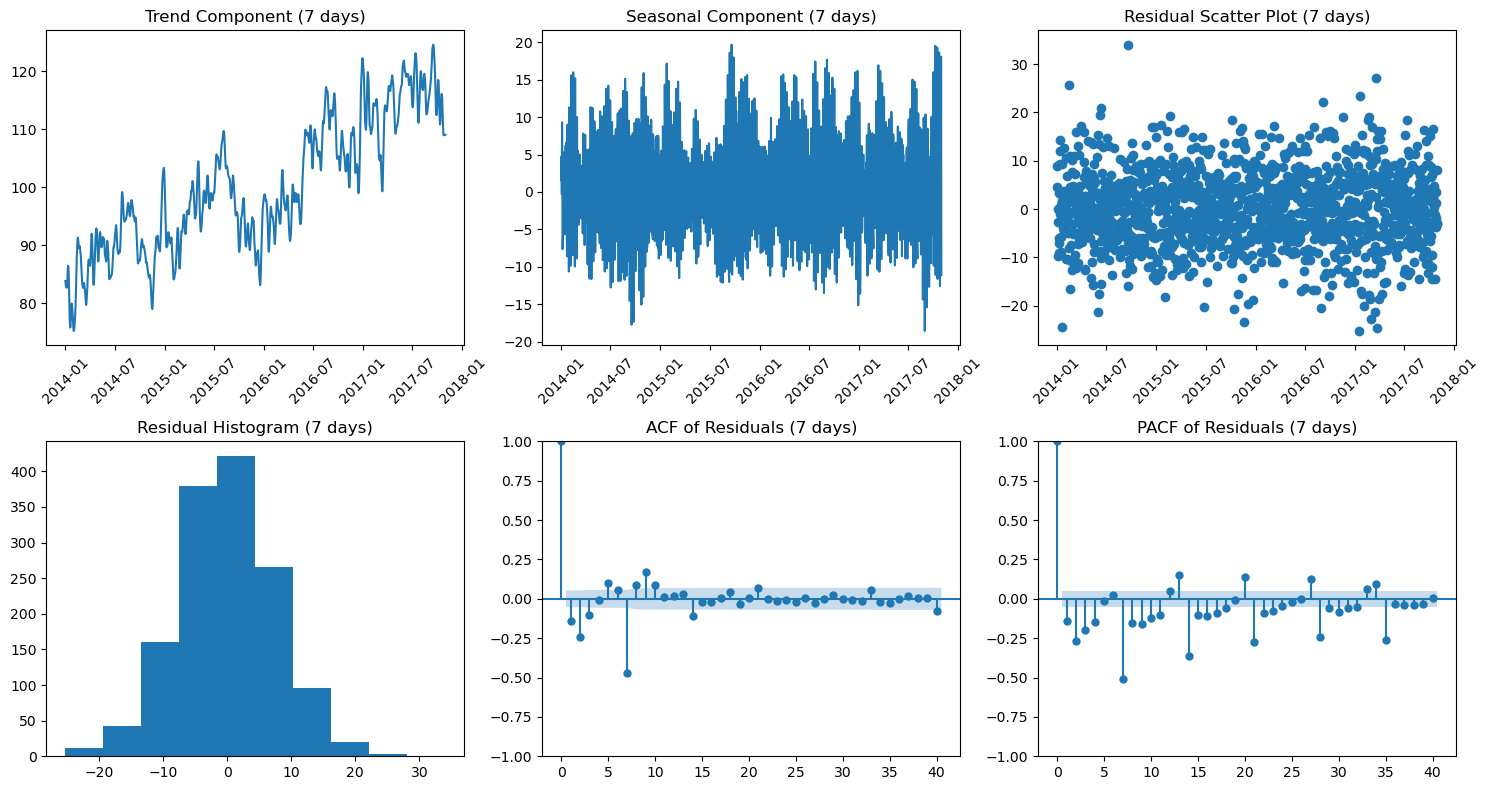

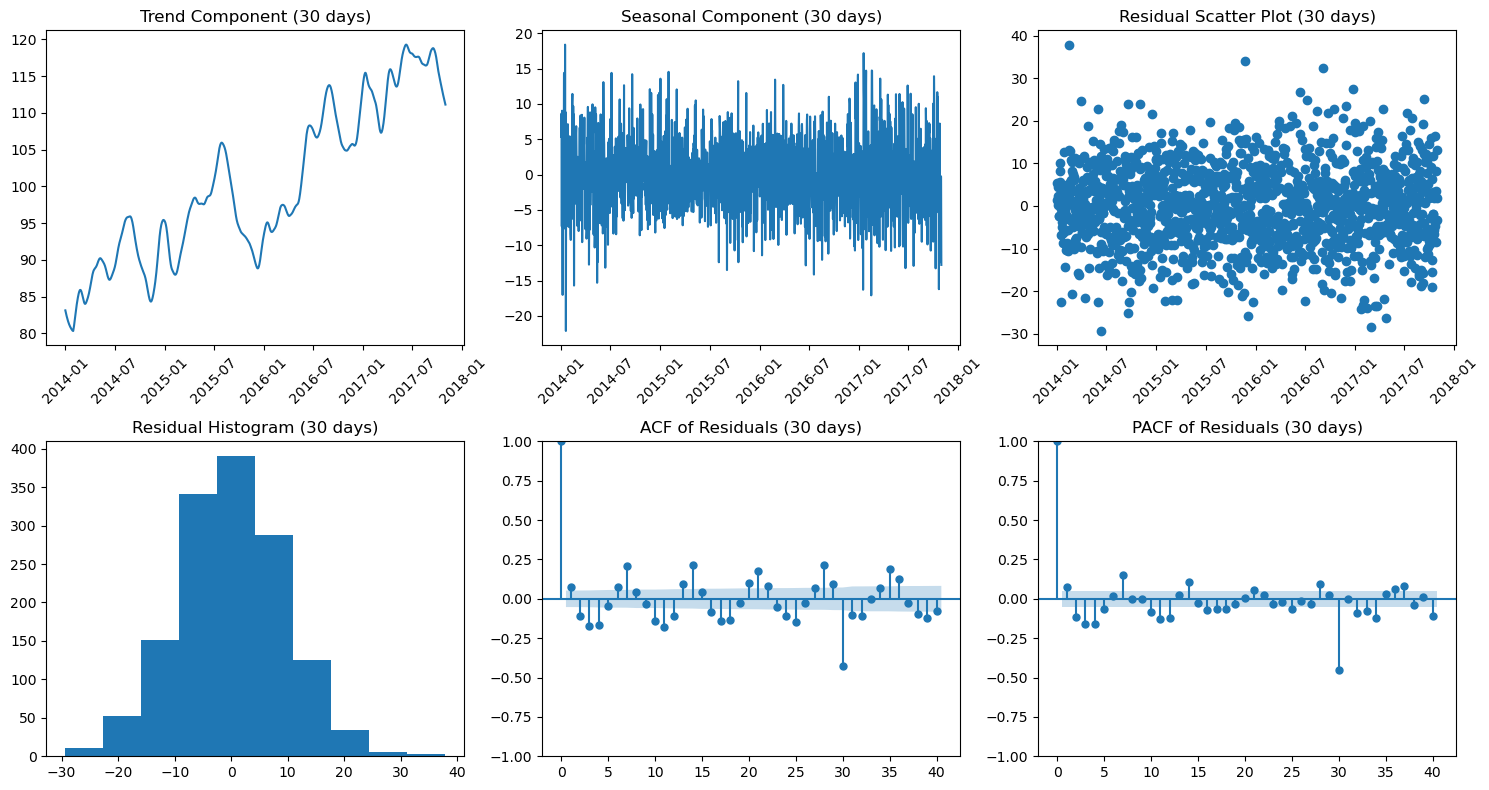

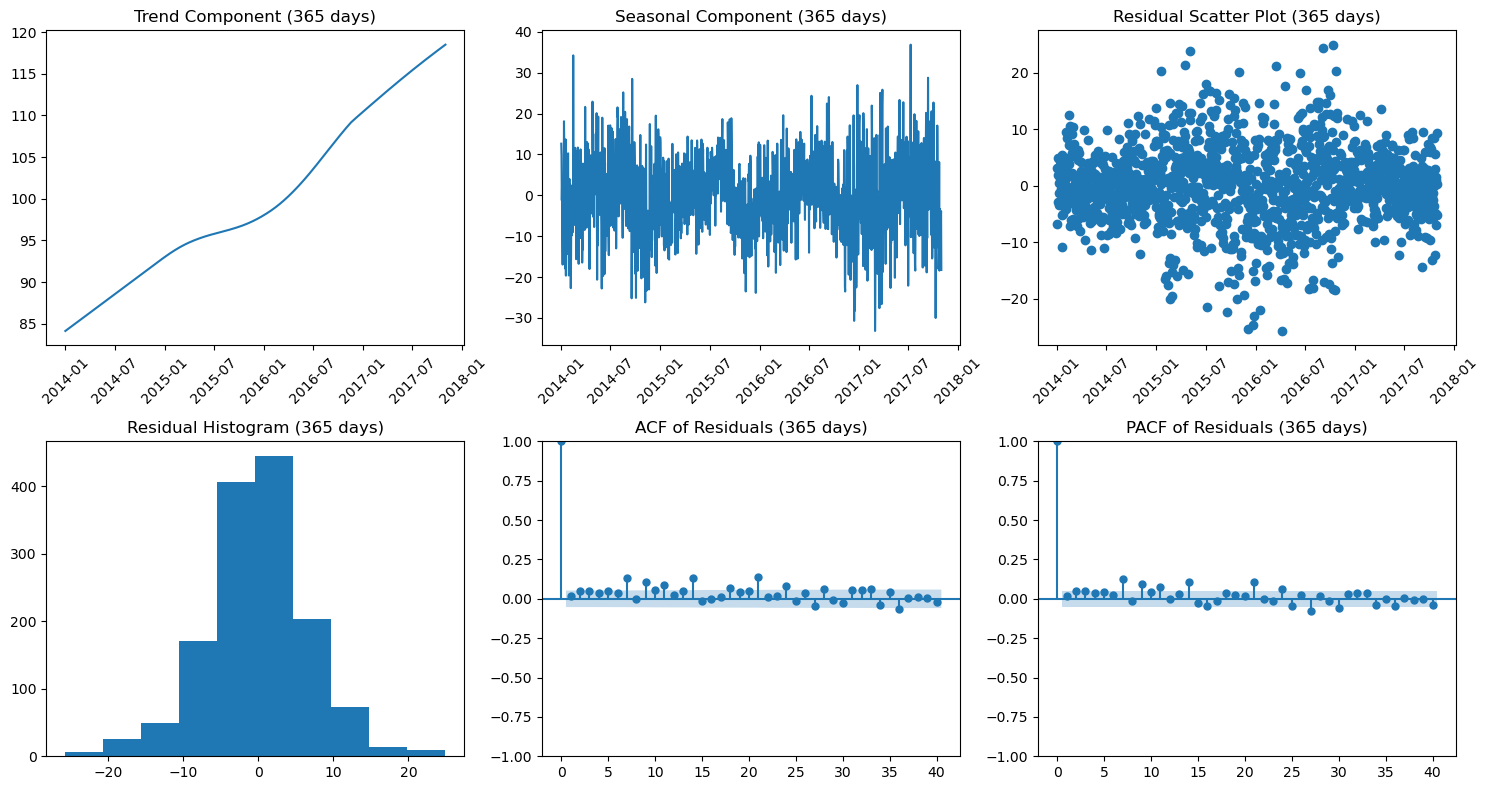

In [ ]:
import matplotlib.pyplot as plt
from sktime.transformations.series.detrend import STLTransformer
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# STL decomposition with three candidate periods
period = [7, 30, 365]

for p in period:
    transformer = STLTransformer(sp=p, return_components=True)
    result = transformer.fit_transform(y)

    # Plot the results
    plt.figure(figsize=(15, 8))
    plt.subplot(2, 3, 1); plt.plot(result.trend); plt.title(f'Trend Component ({p} days)'); plt.xticks(rotation=45)
    plt.subplot(2, 3, 2); plt.plot(result.seasonal); plt.title(f'Seasonal Component ({p} days)'); plt.xticks(rotation=45)
    plt.subplot(2, 3, 3); plt.scatter(result.resid.index,result.resid); plt.title(f'Residual Scatter Plot ({p} days)'); plt.xticks(rotation=45)
    plt.subplot(2, 3, 4); plt.hist(result.resid); plt.title(f'Residual Histogram ({p} days)')
    plt.subplot(2, 3, 5); plot_acf(result.resid.dropna(), lags=40, ax=plt.gca()); plt.title(f'ACF of Residuals ({p} days)')
    plt.subplot(2, 3, 6); plot_pacf(result.resid.dropna(), lags=40, ax=plt.gca()); plt.title(f'PACF of Residuals ({p} days)')
    plt.tight_layout()

**Interpretation**

- **7 days:** some cyclic or seasonal effects remain; the PACF of the residuals still shows a repeating pattern.
- **30 days:** cyclic effects remain in the ACF and PACF every 7 lags.
- **365 days:** no clear cyclic or seasonal effect remains, and the trend shows steady growth.

The **365-day** period is preferred: its residuals have little autocorrelation and look like random
noise, and its trend is smooth and shows the long-term change.

## 3. Exponential smoothing

MAPE for 7 days forecast: 0.047
MAPE for 30 days forecast: 0.103

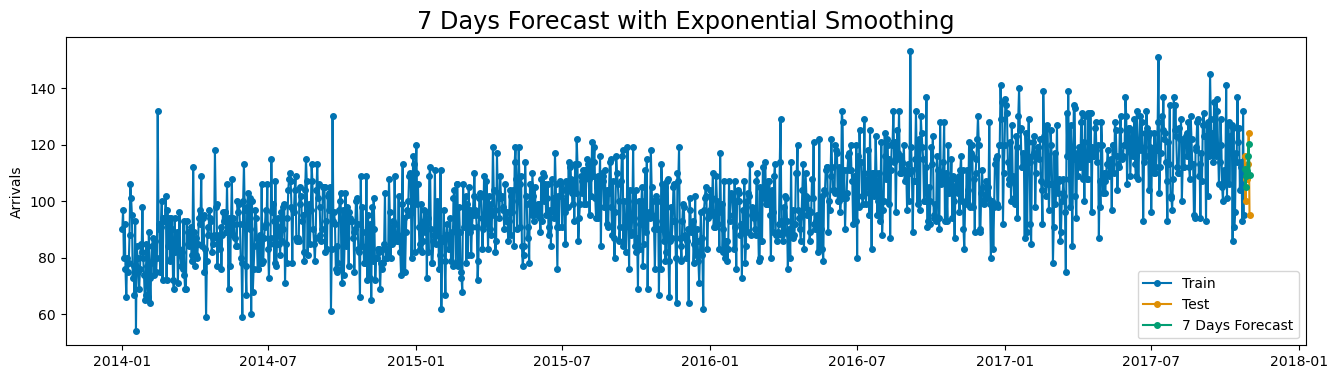

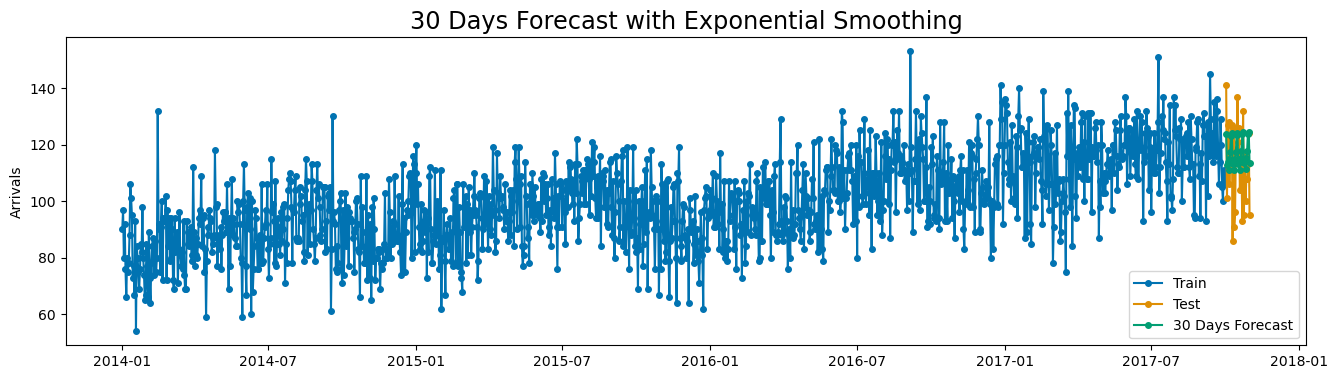

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error
from sktime.forecasting.exp_smoothing import ExponentialSmoothing
from sktime.split import temporal_train_test_split
from sktime.utils.plotting import plot_series

# MAPE is printed as a fraction (0.047 = 4.7%)
for horizon in [7, 30]:
    fh = np.arange(1, horizon + 1)
    train, test = temporal_train_test_split(y, test_size=horizon)

    forecaster_es = ExponentialSmoothing(trend="add", seasonal="multiplicative", sp=7)
    forecaster_es.fit(train)
    pred = forecaster_es.predict(fh=fh)

    plot_series(train, test, pred,
                labels=["Train", "Test", f"{horizon} Days Forecast"],
                title=f"{horizon} Days Forecast with Exponential Smoothing")

    mape = mean_absolute_percentage_error(test, pred)
    print(f"MAPE for {horizon} days forecast: {mape:.3f}")

## 4. ARIMA

In [ ]:
from itertools import product

from sktime.forecasting.arima import ARIMA

p_values = range(0, 5)
d_values = range(0, 5)
q_values = range(0, 5)

for horizon in [7, 30]:
    fh = np.arange(1, horizon + 1)

    # The last 2 x horizon days are held out; the validation window is the `horizon` days before them
    train_val, _ = temporal_train_test_split(y, test_size=2 * horizon)
    train, val = temporal_train_test_split(train_val, test_size=horizon)

    # Grid search over all (p, d, q) with 0 <= p, d, q <= 4, scored by validation MAPE.
    # Only improvements are printed.
    best_cfg, best_mape = None, float("inf")
    for arima_order in product(p_values, d_values, q_values):
        try:
            forecaster = ARIMA(order=arima_order, suppress_warnings=True)
            forecaster.fit(train)
            mape = mean_absolute_percentage_error(val, forecaster.predict(fh=fh))
        except Exception:
            continue  # some orders do not converge
        if mape < best_mape:
            best_cfg, best_mape = arima_order, mape
            print(f"ARIMA{arima_order}, MAPE = {mape:.6f}")

    print(f"Best ARIMA order for {horizon} days forecast is {best_cfg} with MAPE: {best_mape:.3f}\n")

ARIMA(0, 0, 0), MAPE = 0.151503
ARIMA(0, 0, 2), MAPE = 0.149283
ARIMA(0, 0, 3), MAPE = 0.145840
ARIMA(0, 1, 1), MAPE = 0.111730
ARIMA(0, 2, 2), MAPE = 0.111524
ARIMA(2, 1, 4), MAPE = 0.109011
ARIMA(3, 1, 4), MAPE = 0.098418
ARIMA(4, 1, 4), MAPE = 0.098107
Best ARIMA order for 7 days forecast is (4, 1, 4) with MAPE: 0.098

ARIMA(0, 0, 0), MAPE = 0.146450
ARIMA(0, 0, 1), MAPE = 0.145528
ARIMA(0, 0, 2), MAPE = 0.144972
ARIMA(0, 0, 3), MAPE = 0.143568
ARIMA(0, 0, 4), MAPE = 0.143443
ARIMA(0, 1, 0), MAPE = 0.074685
ARIMA(0, 2, 1), MAPE = 0.074462
ARIMA(0, 3, 3), MAPE = 0.073269
ARIMA(1, 0, 4), MAPE = 0.072683
ARIMA(2, 1, 3), MAPE = 0.061243
Best ARIMA order for 30 days forecast is (2, 1, 3) with MAPE: 0.061

Final ARIMA MAPE for 7 days forecast in order (4, 1, 4): 0.071
Final ARIMA MAPE for 30 days forecast in order (2, 1, 3): 0.113

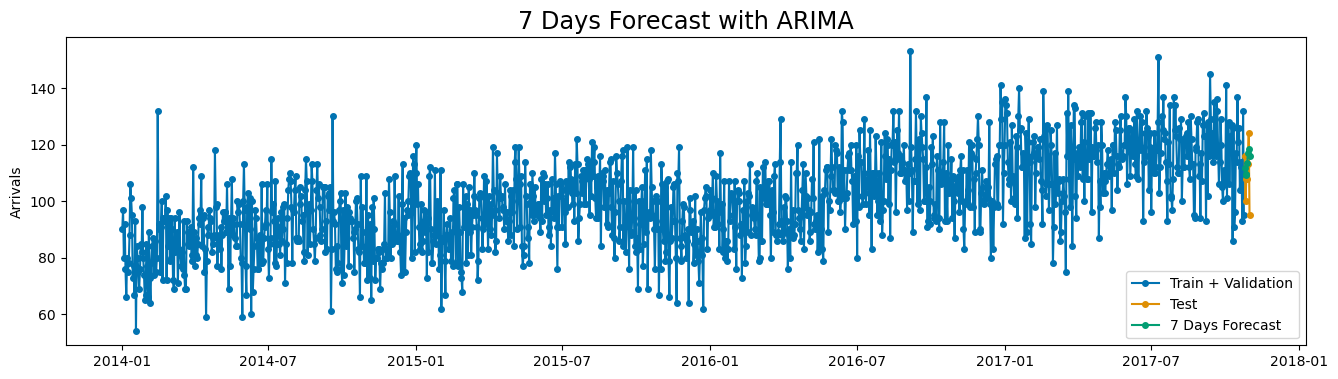

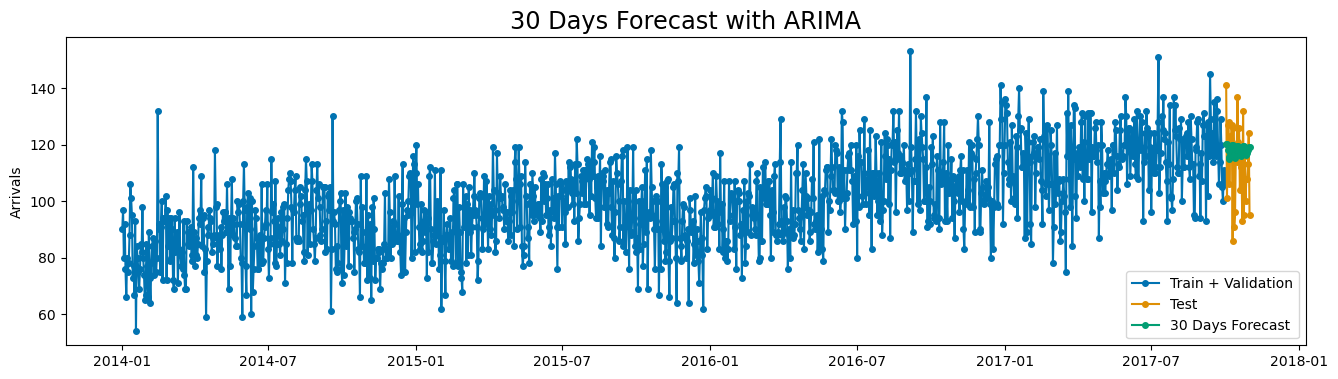

In [ ]:
best_orders = {7: (4, 1, 4), 30: (2, 1, 3)}  # from the search above

for horizon in [7, 30]:
    fh = np.arange(1, horizon + 1)
    train_val, test = temporal_train_test_split(y, test_size=horizon)

    forecaster = ARIMA(order=best_orders[horizon], suppress_warnings=True)
    forecaster.fit(train_val)
    pred = forecaster.predict(fh=fh)

    mape = mean_absolute_percentage_error(test, pred)
    print(f"Final ARIMA MAPE for {horizon} days forecast in order {best_orders[horizon]}: {mape:.3f}")

    plot_series(train_val, test, pred,
                labels=["Train + Validation", "Test", f"{horizon} Days Forecast"],
                title=f"{horizon} Days Forecast with ARIMA")

## 5. KNN regression

7 days best n_neighbors: 11, MAPE: 0.076
30 days best n_neighbors: 11, MAPE: 0.127

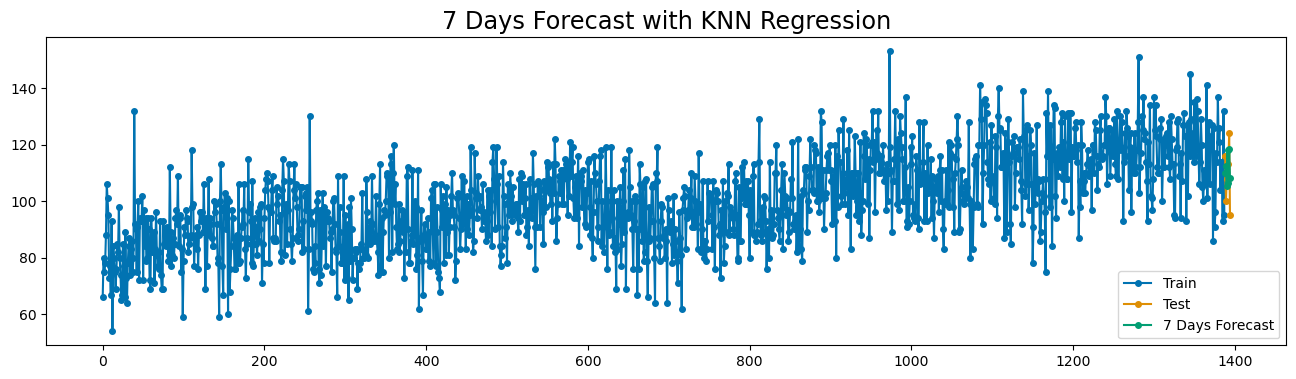

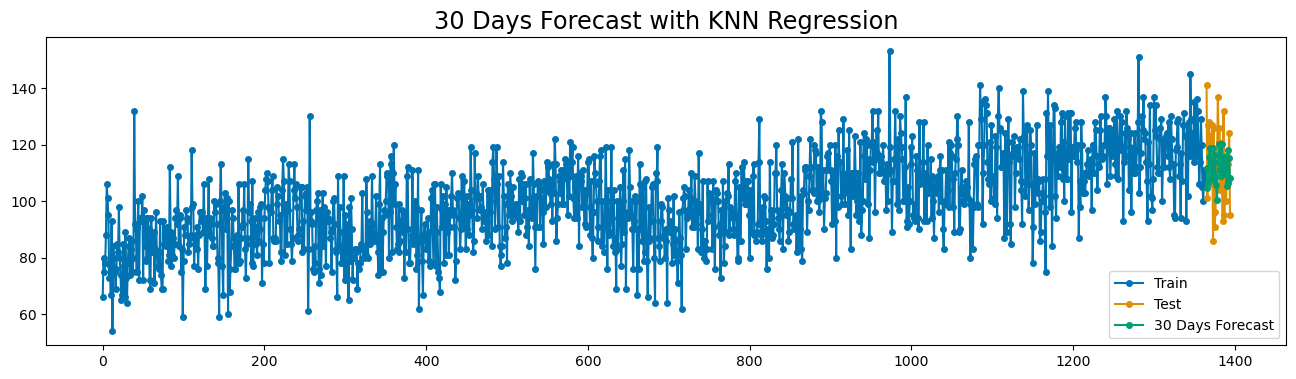

In [ ]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor

N_LAGS = 5


def split_into_train_test(data, in_num, fh):
    """Turns a series into lagged features: each row holds `in_num` past values, the target is the next value.
    The last `fh` targets form the test set. Adapted from the course material."""
    train, test = data[:-fh], data[-(fh + in_num):]
    x_train, y_train = train[:-1], np.roll(train, -in_num)[:-in_num]
    x_test, y_test = test[:-1], np.roll(test, -in_num)[:-in_num]

    x_train = np.reshape(x_train, (-1, 1))
    x_test = np.reshape(x_test, (-1, 1))
    temp_train = np.roll(x_train, -1)
    temp_test = np.roll(x_test, -1)
    for _ in range(1, in_num):
        x_train = np.concatenate((x_train[:-1], temp_train[:-1]), axis=1)
        x_test = np.concatenate((x_test[:-1], temp_test[:-1]), axis=1)
        temp_train = np.roll(temp_train, -1)[:-1]
        temp_test = np.roll(temp_test, -1)[:-1]

    return x_train, y_train, x_test, y_test


for fh in [7, 30]:
    x_train, y_train, x_test, y_test = split_into_train_test(y, N_LAGS, fh)

    # Number of neighbours chosen by grid search with time-ordered 5-fold CV
    grid_search = GridSearchCV(KNeighborsRegressor(), {"n_neighbors": [3, 5, 7, 9, 11]},
                               cv=TimeSeriesSplit(n_splits=5))
    grid_search.fit(x_train, y_train)

    y_pred = grid_search.predict(x_test)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    print(f"{fh} days best n_neighbors: {grid_search.best_params_['n_neighbors']}, MAPE: {mape:.3f}")

    train_index = range(len(y_train))
    test_index = range(len(y_train), len(y_train) + len(y_test))
    plot_series(pd.Series(y_train, index=train_index),
                pd.Series(y_test, index=test_index),
                pd.Series(y_pred, index=test_index),
                labels=["Train", "Test", f"{fh} Days Forecast"],
                title=f"{fh} Days Forecast with KNN Regression")

## Summary (test MAPE)

| Method | 7 days | 30 days |
|---|---|---|
| Exponential smoothing | **4.7%** | **10.3%** |
| ARIMA | 7.1% | 11.3% |
| KNN regression | 7.6% | 12.7% |

Exponential smoothing is the most accurate on both horizons. Each horizon has a single test window,
so the ranking is indicative only.